### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

### Auxiliary functions

In [2]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe
def fixed_size_subframes(data):
    n = 257
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]


def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        cleaned_df = df[mask]
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes


def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()
   
 
def create_features_and_targets(subframes):
    feature_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    target_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    X_chunks = []
    y_chunks = []

    for df in subframes:    
        first_row = df.iloc[0][feature_labels].values
        
        X_chunk = np.column_stack((df['t'].values, np.tile(first_row, (len(df), 1))))
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        y_chunk_df = df[target_labels].copy()
        
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)

    return X_chunks, y_chunks


def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None

    for degree in degrees:
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train, y_train)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        y_pred = polyreg.predict(X_val)
        
        rmse = root_mean_squared_error(y_val, y_pred)
        
        print(f"Degree {degree}: {n_features} features | RMSE: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


def degree_distribution_histogram(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9)):
    degree_counts = {degree: 0 for degree in degrees}

    for run in range(10):
        X_train_sample, y_train_sample = resample(X_train, y_train, n_samples=int(0.01 * len(X_train)))
        _, degree, _ = validate_poly_regression(X_train_sample, y_train_sample, X_val, y_val, regressor=regressor, degrees=degrees)
        degree_counts[degree] += 1
    
    plt.bar(degree_counts.keys(), degree_counts.values())
    plt.xlabel('Polynomial Degree')
    plt.ylabel('Frequency of Selection')
    plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
    plt.show()


def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions['Id'] = df_positions.index
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions.to_csv(path, index=False)

## Pre-processing

### Load the dataset (without velocities)

In [3]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True)
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


### Split dataset into list of simulations (removing all null rows and null scenarios)

In [4]:
subframes = fixed_size_subframes(df)
subframes = remove_useless_rows(subframes)
subframes[0].head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


### Extract features and targets from the dataset

In [5]:
X_chunks, y_chunks = create_features_and_targets(subframes)

### Train test split (80% training, 10% validation, 10% test)

In [6]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

# Task 2: Nonlinear models on the data — the Polynomial model

## Task 2.1 Development

10 runs of linear regression on polynomial features up to degree 8

Degree 1: 7 features | RMSE: 1.376917833402777
Degree 2: 35 features | RMSE: 1.3508131826628655
Degree 3: 119 features | RMSE: 1.3164568677185047
Degree 4: 329 features | RMSE: 1.5193310652978667
Degree 5: 791 features | RMSE: 1.3544580327243005
Degree 6: 1715 features | RMSE: 2.1976146068402342
Degree 7: 3431 features | RMSE: 1.9843156388884369
Degree 8: 6434 features | RMSE: 1.734547063520542
Best Degree: 3, RMSE: 1.3164568677185047
Degree 1: 7 features | RMSE: 1.3769593711148496
Degree 2: 35 features | RMSE: 1.3535426195198303
Degree 3: 119 features | RMSE: 1.318983748851128
Degree 4: 329 features | RMSE: 1.2930995855372815
Degree 5: 791 features | RMSE: 1.3129367295609669
Degree 6: 1715 features | RMSE: 1.2585933274700023
Degree 7: 3431 features | RMSE: 1.2619542669825823
Degree 8: 6434 features | RMSE: 1.2460248224067336
Best Degree: 8, RMSE: 1.2460248224067336
Degree 1: 7 features | RMSE: 1.3759670183829298
Degree 2: 35 features | RMSE: 1.34948930740787
Degree 3: 119 features | R

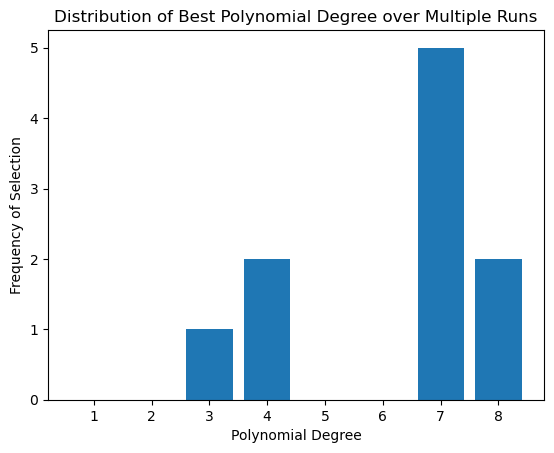

In [7]:
degree_distribution_histogram(X_train, y_train, X_dev, y_dev, regressor=LinearRegression(), degrees=range(1, 9))

10 runs of Ridge regularization with Cross Validation on polynomial features up to degree 8

Degree 1: 7 features | RMSE: 1.3779605187632484
Degree 2: 35 features | RMSE: 1.3530313013445914
Degree 3: 119 features | RMSE: 1.3142434740002424
Degree 4: 329 features | RMSE: 1.2811104994310891
Degree 5: 791 features | RMSE: 1.2669160864027953
Degree 6: 1715 features | RMSE: 1.2479772236167321
Degree 7: 3431 features | RMSE: 1.2312209521735797
Degree 8: 6434 features | RMSE: 1.24026691568362
Best Degree: 7, RMSE: 1.2312209521735797
Degree 1: 7 features | RMSE: 1.3772234970578132
Degree 2: 35 features | RMSE: 1.3519665061052464
Degree 3: 119 features | RMSE: 1.3139271925186795
Degree 4: 329 features | RMSE: 1.2796894419110076
Degree 5: 791 features | RMSE: 1.2632744392225728
Degree 6: 1715 features | RMSE: 1.2434490924328465
Degree 7: 3431 features | RMSE: 1.2227696886908894
Degree 8: 6434 features | RMSE: 1.21271972983929
Best Degree: 8, RMSE: 1.21271972983929
Degree 1: 7 features | RMSE: 1.3763880497795238
Degree 2: 35 features | RMSE: 1.3512152476252404
Degree 3: 119 features | RM

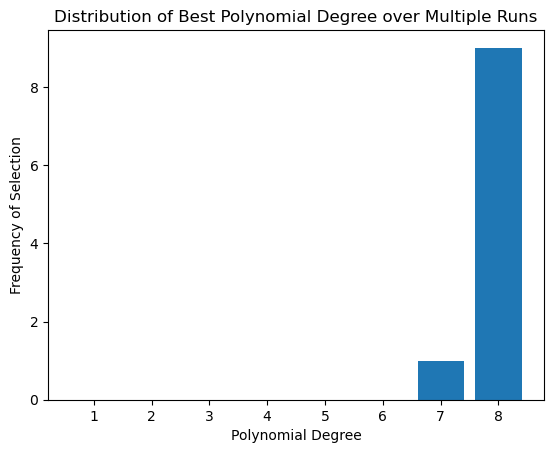

In [8]:
degree_distribution_histogram(X_train, y_train, X_dev, y_dev, regressor=RidgeCV(), degrees=range(1, 9))

## Task 2.2 Evaluation

### Compare RMSE and the y-y hat plots

### Linear regression

Best poly model with linear regression (degree 7)

In [9]:
degree=7

polyreg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

polyreg.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures',
                 PolynomialFeatures(degree=7, include_bias=False)),
                ('linearregression', LinearRegression())])

Plot y-y hat in validation set and RMSE

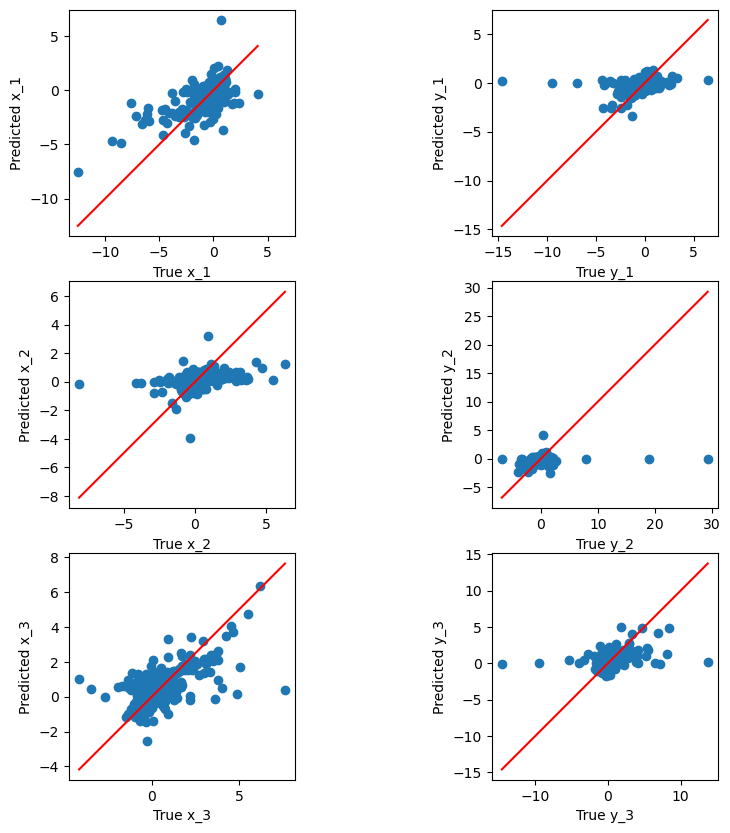

Validation RMSE: 1.2422119947066574


In [10]:
y_dev_pred = polyreg.predict(X_dev)

plot_y_yhat(y_dev.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev, y_dev_pred)

print(f"Validation RMSE: {rmse}")

Plot y-y hat in test set and present RMSE

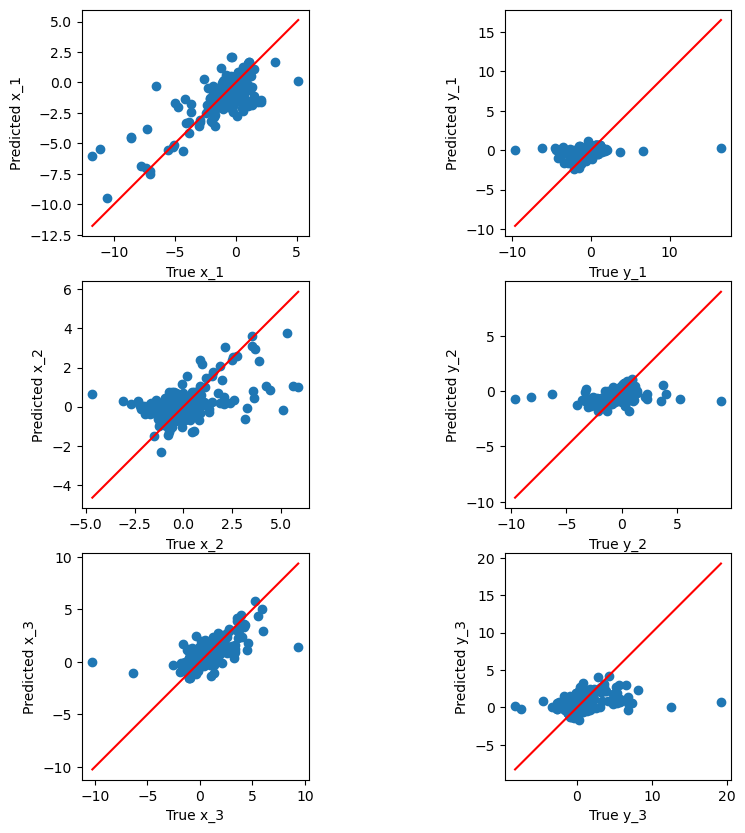

Test RMSE: 1.275899321648298


In [11]:
y_test_pred = polyreg.predict(X_test)

plot_y_yhat(y_test.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Test RMSE: {rmse}")

Save the prediction

In [12]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

y_polynomial_pred = polyreg.predict(X_kaggle_df)
save_predictions(y_polynomial_pred, '../submissions/polynomial_submission.csv')

Save the model

In [13]:
save_model(polyreg, "polynomial_model.onnx", X_kaggle_df)

<class 'sklearn.pipeline.Pipeline'>


### RidgeCV

Best poly model with RidgeCV (degree 8) but can only run up to 6

In [14]:
degree = 6

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train, y_train)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev)

Plot y-y hat and RMSE in validation set

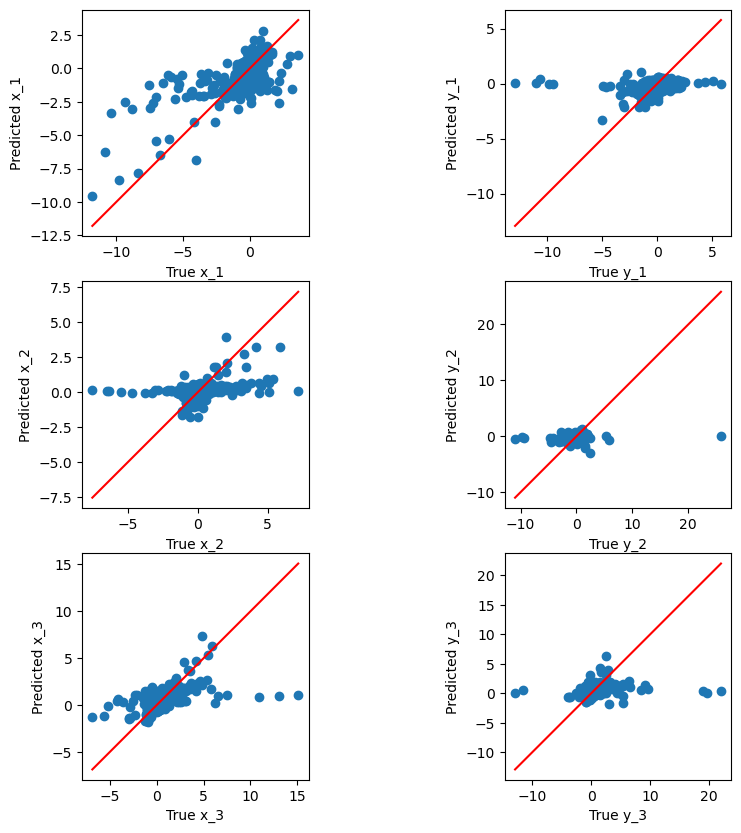

Validation RMSE: 1.2394613364747873


In [15]:
y_dev_pred = polyreg.predict(X_dev)

plot_y_yhat(y_dev.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev, y_dev_pred)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE in test set

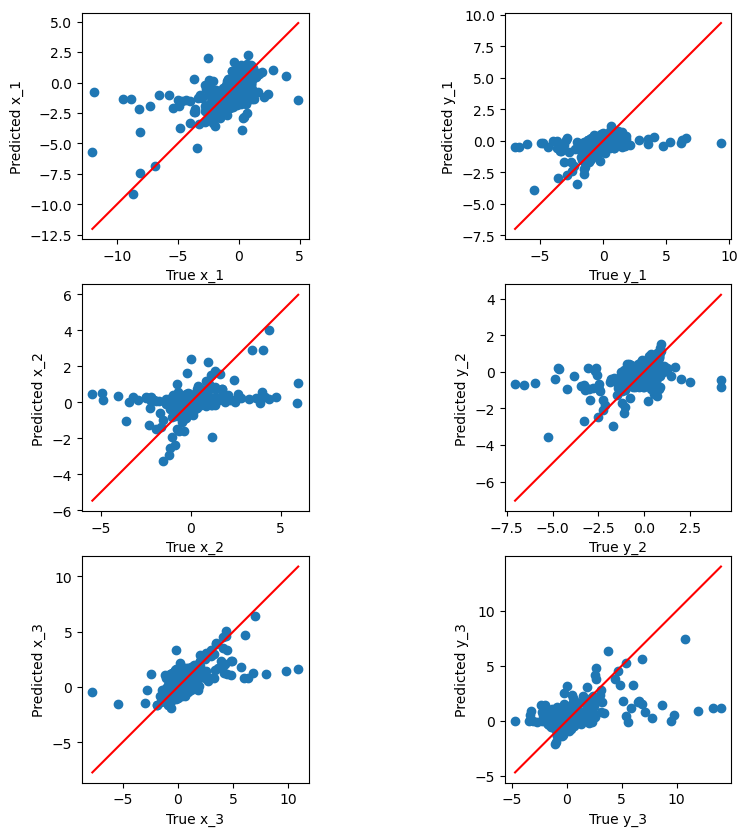

Test RMSE: 1.2953546399343392


In [16]:
y_test_pred = polyreg.predict(X_test)

plot_y_yhat(y_test.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Test RMSE: {rmse}")

Save the prediction

In [17]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

y_polynomial_pred = polyreg.predict(X_kaggle_df)
save_predictions(y_polynomial_pred, '../submissions/polynomial_submission.csv')